# 10. Development Cost Function Tests

This notebook runs three development-cost functions: the current constant cost, a linearly rising marginal cost, and a quadratically rising marginal cost. The income equation, starting regional values, mitigation costs, pollution dynamics, damage settings, and fixed policies stay the same. Only the development-cost curve changes.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from study_3_pollutant_dynamics.config import EnvironmentConfig
from study_3_pollutant_dynamics.baseline_regression import (REFERENCE_BASELINE_SETTINGS, REFERENCE_BASELINE_POLICIES,
                                                            compare_reference_baseline)
from study_3_pollutant_dynamics.integrated_environment import Study3IntegratedEnvironment
from study_3_pollutant_dynamics.development_costs import DEVELOPMENT_COST_SHAPES
from study_3_pollutant_dynamics.policy_evaluation import (FIXED_POLICY_NAMES, run_fixed_policy_episode, summarize_integrated_episode)

from study_3_pollutant_dynamics.scenario_parameters import get_parameters
from study_3_pollutant_dynamics.economic_parameters import REGIONAL_ECONOMIC_PARAMETERS

## Cost equations

Let `x = (EDI - initial_EDI) / (100 - initial_EDI)`. The price of a one-point development action is

- Constant: `C = 25`
- Linear: `C = 25 * (1 + x)`
- Quadratic: `C = 25 * (1 + x)^2`

Each function starts at the existing 25-unit price when EDI equals its regional starting value. The linear and quadratic functions increase the marginal price as EDI rises. These shapes test financial consequences; they are not empirical estimates.

## Matched episode runs

Every episode uses the proposed starting currency for each region (1.0x), the reference pollutant and damage settings, and the existing purchase schedule. The fixed policy makes the same choices for each cost curve. Because the model is deterministic, the same seed is used for reproducibility rather than as a source of variation.

Cumulative income sums each region's annual net income across the full episode. The missed-purchase-cycle count compares completed packages with the ideal five-year schedule; failed purchase attempts also count retries that may later succeed.

In [2]:
HORIZONS = [20, REFERENCE_BASELINE_SETTINGS["episode_steps"], 60]
POLICIES = []

for policy_name in FIXED_POLICY_NAMES:
    if policy_name in REFERENCE_BASELINE_POLICIES:
        POLICIES.append(policy_name)
STARTING_CURRENCY_MULTIPLIER = REFERENCE_BASELINE_SETTINGS["starting_currency_multiplier"]
PURCHASE_FREQUENCY_YEARS = 5

In [3]:
result_rows = []
trajectory_results = {}

for cost_shape in DEVELOPMENT_COST_SHAPES:
    for policy_name in POLICIES:
        for horizon in HORIZONS:
            config = EnvironmentConfig(get_parameters(episode_steps=horizon))
            environment = Study3IntegratedEnvironment(config, starting_currency_multiplier=STARTING_CURRENCY_MULTIPLIER,
                                                      development_cost_shape=cost_shape, development_cost_multiplier=REFERENCE_BASELINE_SETTINGS["development_cost_multiplier"],
                                                      investment_cost_multiplier=REFERENCE_BASELINE_SETTINGS["investment_cost_multiplier"],
                                                      income_damage_multiplier=REFERENCE_BASELINE_SETTINGS["income_damage_multiplier"],
                                                      income_damage_persistence=REFERENCE_BASELINE_SETTINGS["income_damage_persistence"])
            trajectory, terminated, truncated = run_fixed_policy_episode(policy_name, environment, seed=REFERENCE_BASELINE_SETTINGS["seed"])
            summary = summarize_integrated_episode(policy_name, trajectory, environment)

            cumulative_gross_income = 0.0
            cumulative_net_income = 0.0
            for info in trajectory:
                for region_result in info["regional_economy"]:
                    cumulative_gross_income += region_result["gross_income"]
                    cumulative_net_income += region_result["net_income"]

            planned_purchase_cycles = 0
            if policy_name in ("balanced", "cleanup_focused"):
                cycles_per_region = (horizon + PURCHASE_FREQUENCY_YEARS - 1) // PURCHASE_FREQUENCY_YEARS
                planned_purchase_cycles = cycles_per_region * len(environment.regions)

            completed_purchase_cycles = summary["investment_package_purchases"]
            missed_purchase_cycles = max(0, planned_purchase_cycles - completed_purchase_cycles)
            summary["horizon_years"] = horizon
            summary["cumulative_gross_income"] = cumulative_gross_income
            summary["cumulative_net_income"] = cumulative_net_income
            summary["mean_cumulative_net_income_per_region"] = (cumulative_net_income / len(environment.regions))
            summary["planned_purchase_cycles"] = planned_purchase_cycles
            summary["completed_purchase_cycles"] = completed_purchase_cycles
            summary["missed_purchase_cycles"] = missed_purchase_cycles
            summary["failed_purchase_attempts_including_retries"] = (summary["unaffordable_investment_attempts"])
            summary["terminated"] = terminated
            summary["completed_horizon"] = truncated
            result_rows.append(summary)
            trajectory_results[(cost_shape, policy_name, horizon)] = trajectory

cost_results = pd.DataFrame(result_rows)
print(f"Completed {len(cost_results)} matched episodes.")

Completed 27 matched episodes.


## Development and income outcomes

Final EDI, cumulative income, currency, and development spending show whether a rising cost changes long-term development or mainly shifts when regions reach the target. Cumulative income is net of the existing pollution-damage function.

In [4]:
economic_columns = ["development_cost_shape", "policy", "horizon_years", "final_mean_EDI",
                    "final_min_EDI", "cumulative_net_income", "final_mean_currency",
                    "minimum_currency", "development_spending", "unaffordable_development_attempts"]

economic_results = cost_results[economic_columns].sort_values(["policy", "horizon_years", "development_cost_shape"])
display(economic_results.round(2))

,development_cost_shape,policy,horizon_years,final_mean_EDI,final_min_EDI,cumulative_net_income,final_mean_currency,minimum_currency,development_spending,unaffordable_development_attempts
6,constant,balanced,20,85.00,75.0,7554.05,1213.51,275.61,2000.00,0
15,linear,balanced,20,85.00,75.0,7554.05,1070.35,275.61,2572.64,0
24,quadratic,balanced,20,85.00,75.0,7554.05,868.07,275.61,3381.78,0
7,constant,balanced,40,98.75,95.0,18216.61,2735.40,275.61,3375.00,0
16,linear,balanced,40,98.75,95.0,18216.61,2339.57,275.61,4958.33,0
25,quadratic,balanced,40,98.75,95.0,18216.61,1691.70,275.61,7549.82,0
8,constant,balanced,60,100.00,100.0,30768.48,5042.12,275.61,3500.00,0
17,linear,balanced,60,100.00,100.0,30768.48,4617.12,275.61,5200.00,0
26,quadratic,balanced,60,100.00,100.0,30768.48,3912.83,275.61,8017.17,0
3,constant,cleanup_focused,20,85.00,75.0,7231.11,1532.78,375.61,2000.00,0


## Shared baseline regression check

The constant-cost, 40-year, 1.0-currency rows should match Notebook 09 for development-only, balanced, and cleanup-focused policies. This check compares the refreshed episode results with the shared expected values in `baseline_regression.py`.

In [5]:
shared_baseline_rows = []
for result_row in cost_results.to_dict("records"):
    matching_cost = result_row["development_cost_shape"] == REFERENCE_BASELINE_SETTINGS["development_cost_shape"]
    matching_horizon = result_row["horizon_years"] == REFERENCE_BASELINE_SETTINGS["episode_steps"]
    matching_policy = result_row["policy"] in REFERENCE_BASELINE_POLICIES
    if matching_cost and matching_horizon and matching_policy:
        shared_baseline_rows.append(result_row)

baseline_check_rows = compare_reference_baseline(shared_baseline_rows)
baseline_checks = pd.DataFrame(baseline_check_rows)
display(baseline_checks)

,policy,metric,expected,actual,passed
0,development_only,final_mean_EDI,98.750000,98.750000,True
1,development_only,final_min_EDI,95.000000,95.000000,True
2,development_only,final_mean_currency,3744.507401,3744.507401,True
3,development_only,minimum_currency,475.605311,475.605311,True
4,development_only,development_spending,3375.000000,3375.000000,True
5,development_only,mitigation_spending,0.000000,0.000000,True
6,development_only,investment_package_purchases,0.000000,0.000000,True
7,development_only,unaffordable_development_attempts,0.000000,0.000000,True
8,development_only,final_CO2_ppm,529.662055,529.662055,True
9,development_only,final_mean_PM2.5_ug_m3,8.613520,8.613520,True


In [6]:
passed_checks = int(baseline_checks["passed"].sum())
total_checks = len(baseline_checks)

print(f"Passed {passed_checks} of {total_checks} shared baseline checks.")
if passed_checks != total_checks:
    raise ValueError("Notebook 10 baseline changed; review the current model and update the regression fixture only if intended.")

Passed 36 of 36 shared baseline checks.


Read EDI together with cumulative income and currency. If a policy reaches similar EDI under a higher-cost curve, check whether it takes longer, uses more income, or leaves fewer resources for mitigation. Development spending rises automatically with the marginal cost function.

## Mitigation purchases and environmental outcomes

For balanced and cleanup-focused policies, compare planned purchase cycles, completed packages, missed cycles, and failed attempts. Failed attempts include repeated tries before a later purchase. The final pollution table keeps each pollutant in its modeled units.

In [7]:
purchase_columns = ["development_cost_shape", "policy", "horizon_years", "planned_purchase_cycles",
                    "completed_purchase_cycles", "missed_purchase_cycles", "failed_purchase_attempts_including_retries",
                    "mitigation_spending"]

purchase_results = cost_results[purchase_columns].sort_values(["policy", "horizon_years", "development_cost_shape"])
display(purchase_results.round(2))

,development_cost_shape,policy,horizon_years,planned_purchase_cycles,completed_purchase_cycles,missed_purchase_cycles,failed_purchase_attempts_including_retries,mitigation_spending
6,constant,balanced,20,16,16,0,0,3200.0
15,linear,balanced,20,16,16,0,0,3200.0
24,quadratic,balanced,20,16,16,0,0,3200.0
7,constant,balanced,40,32,32,0,0,6400.0
16,linear,balanced,40,32,32,0,0,6400.0
25,quadratic,balanced,40,32,32,0,0,6400.0
8,constant,balanced,60,48,48,0,0,9600.0
17,linear,balanced,60,48,48,0,0,9600.0
26,quadratic,balanced,60,48,48,0,0,9600.0
3,constant,cleanup_focused,20,16,16,0,0,1600.0


A missed cycle means that fewer packages were bought than under the ideal five-year schedule by the end of the episode. A policy can have several failed attempts but still complete that cycle later, so the retry count and missed-cycle count answer different questions.

In [8]:
environment_columns = ["development_cost_shape", "policy", "horizon_years", "final_CO2_ppm",
                       "final_mean_PM2.5_ug_m3", "final_mean_nitrate_mg_N_L", "final_mean_lead_total_kg",
                       "final_mean_lead_mobile_kg"]

environment_results = cost_results[environment_columns].sort_values(["policy", "horizon_years", "development_cost_shape"])
display(environment_results.round(4))

,development_cost_shape,policy,horizon_years,final_CO2_ppm,final_mean_PM2.5_ug_m3,final_mean_nitrate_mg_N_L,final_mean_lead_total_kg,final_mean_lead_mobile_kg
6,constant,balanced,20,475.2626,8.5535,2.1013,12.1450,0.0012
15,linear,balanced,20,475.2626,8.5535,2.1013,12.1450,0.0012
24,quadratic,balanced,20,475.2626,8.5535,2.1013,12.1450,0.0012
7,constant,balanced,40,526.6103,8.5701,2.4450,11.7073,0.0011
16,linear,balanced,40,526.6103,8.5701,2.4450,11.7073,0.0011
25,quadratic,balanced,40,526.6103,8.5701,2.4450,11.7073,0.0011
8,constant,balanced,60,578.4595,8.5724,2.4937,11.4149,0.0011
17,linear,balanced,60,578.4595,8.5724,2.4937,11.4149,0.0011
26,quadratic,balanced,60,578.4595,8.5724,2.4937,11.4149,0.0011
3,constant,cleanup_focused,20,476.7145,8.5913,2.6572,12.6775,0.0049


## Development by horizon

These panels compare mean final EDI across the three horizons. A persistent gap at 60 years indicates that higher marginal costs continue to constrain the fixed policy. A gap at 20 years that narrows by 40 or 60 years indicates delay rather than a lasting development limit.

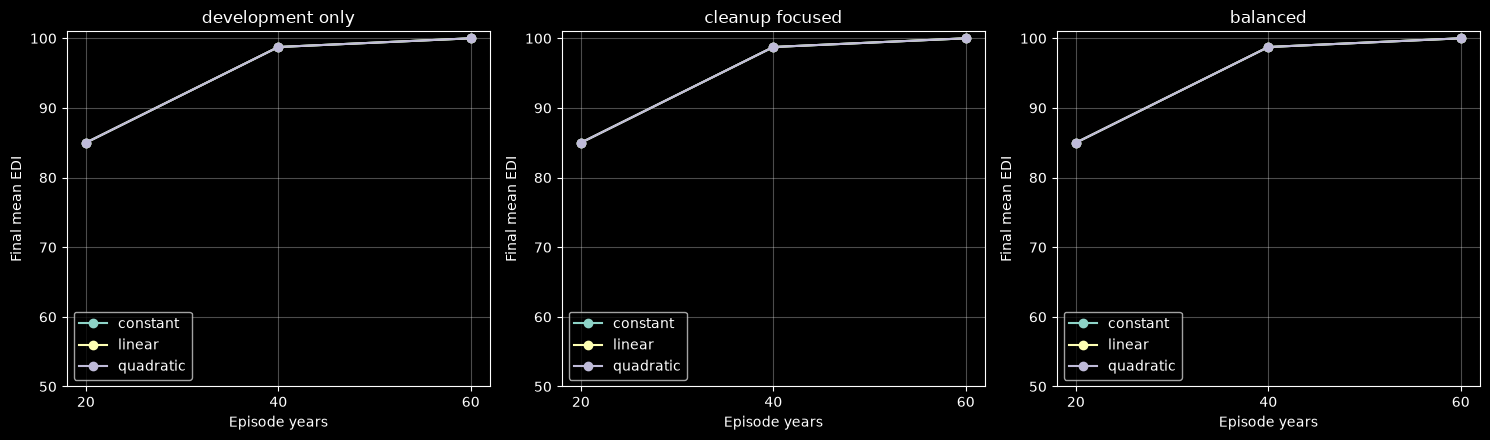

In [9]:
figure, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for axis_index, policy_name in enumerate(POLICIES):
    axis = axes[axis_index]
    for cost_shape in DEVELOPMENT_COST_SHAPES:
        policy_rows = cost_results[(cost_results["policy"] == policy_name)
                                   & (cost_results["development_cost_shape"] == cost_shape)].sort_values("horizon_years")
        axis.plot(policy_rows["horizon_years"], policy_rows["final_mean_EDI"], marker="o",
                  label=cost_shape)
    axis.set_title(policy_name.replace("_", " "))
    axis.set_xlabel("Episode years")
    axis.set_ylabel("Final mean EDI")
    axis.set_xticks(HORIZONS)
    axis.set_ylim(50, 101)
    axis.grid(True, alpha=0.3)
    axis.legend()

figure.tight_layout()
plt.show()

## What stands out

All three cost curves end at the same mean EDI for every policy: 85 at year 20, 98.75 at year 40, and 100 at year 60. No development attempts are unaffordable, and balanced and cleanup-focused complete every scheduled purchase cycle. The rising cost curves therefore do not limit development under these starting resources and income assumptions.

They do reduce remaining currency. At year 60, quadratic development spending is 8,017 units, compared with 3,500 under constant cost. Under balanced, final mean currency is 3,913 with quadratic cost and 5,042 with constant cost; both spend 9,600 on mitigation. Pollution outcomes are identical across cost shapes within each policy because the regions follow the same EDI and investment paths.

## Numerical and resource checks

The cost curve changes prices only. Every episode should still complete its configured horizon, keep currency and pollutant stocks nonnegative, keep EDI in range, and preserve nitrate and lead mass accounting.

In [10]:
check_rows = []
for row in result_rows:
    check_rows.append({
        "cost_shape": row["development_cost_shape"],
        "policy": row["policy"],
        "horizon_years": row["horizon_years"],
        "completed_horizon": row["completed_horizon"],
        "currency_nonnegative": row["minimum_currency"] >= -1e-9,
        "pollutant_stocks_nonnegative": row["pollutant_stocks_nonnegative"],
        "state_values_finite": row["state_values_finite"],
        "EDI_within_0_100": row["maximum_EDI"] <= 100 and row["final_min_EDI"] >= 0,
        "nitrate_mass_balance_ok": row["maximum_nitrate_mass_balance_residual_kg"] < 1e-5,
        "lead_mass_balance_ok": row["maximum_lead_mass_balance_residual_kg"] < 1e-9,
    })

In [11]:
checks = pd.DataFrame(check_rows)
check_columns = [
    "completed_horizon",
    "currency_nonnegative",
    "pollutant_stocks_nonnegative",
    "state_values_finite",
    "EDI_within_0_100",
    "nitrate_mass_balance_ok",
    "lead_mass_balance_ok",
]

display(checks)
passed_checks = int(checks[check_columns].sum().sum())
total_checks = len(checks) * len(check_columns)
print(f"Passed {passed_checks} of {total_checks} checks.")

,cost_shape,policy,horizon_years,completed_horizon,currency_nonnegative,pollutant_stocks_nonnegative,state_values_finite,EDI_within_0_100,nitrate_mass_balance_ok,lead_mass_balance_ok
0,constant,development_only,20,True,True,True,True,True,True,True
1,constant,development_only,40,True,True,True,True,True,True,True
2,constant,development_only,60,True,True,True,True,True,True,True
3,constant,cleanup_focused,20,True,True,True,True,True,True,True
4,constant,cleanup_focused,40,True,True,True,True,True,True,True
5,constant,cleanup_focused,60,True,True,True,True,True,True,True
6,constant,balanced,20,True,True,True,True,True,True,True
7,constant,balanced,40,True,True,True,True,True,True,True
8,constant,balanced,60,True,True,True,True,True,True,True
9,linear,development_only,20,True,True,True,True,True,True,True


Passed 189 of 189 checks.


## Interpretation and limits

The three cost curves isolate how development pricing interacts with the same income, mitigation, environmental dynamics, and fixed policies. The horizon comparison is especially important: income compounds over time, so a quadratic cost may slow development at first but cease to bind later. Report a lasting constraint only if the final EDI gap remains at 60 years.

## Why do regions afford EDI 100?

I trace the 60-year development requests for each cost shape and policy. A development action is paid from currency available at the start of the year,  that year's income is added only after development and mitigation spending. The tables compare accumulated net income and starting currency with development spending, count failed requests, and show the smallest starting-currency-to-cost ratio. Below 1.25 is shown as a narrow affordability margin.

In [12]:
def calculate_regional_affordability(trajectory, region_index, region, cost_shape, policy_name):
    regional_income = 0.0
    regional_development_spending = 0.0
    regional_requests = 0
    regional_affordable_requests = 0
    regional_unaffordable_requests = 0
    regional_near_binding_requests = 0

    regional_lowest_ratio = float("inf")
    regional_lowest_year = 0
    tightest_development_request = None

    plot_rows = []

    for info in trajectory:
        region_result = info["regional_economy"][region_index]

        regional_income += region_result["net_income"]
        regional_development_spending += region_result["development_cost"]

        if region_result["development_requested"]:
            regional_requests += 1

            request_cost = region_result["development_requested_cost"]
            opening_currency = region_result["currency_before_actions"]
            affordability_ratio = opening_currency / request_cost

            if region_result["development_affordable"]:
                regional_affordable_requests += 1
            else:
                regional_unaffordable_requests += 1

            if affordability_ratio < 1.25:
                regional_near_binding_requests += 1

            if affordability_ratio < regional_lowest_ratio:
                regional_lowest_ratio = affordability_ratio
                regional_lowest_year = region_result["year"]
                tightest_development_request = region_result

            if cost_shape == "quadratic":
                plot_rows.append({
                    "policy": policy_name,
                    "region": region["region"],
                    "year": region_result["year"],
                    "affordability_ratio": affordability_ratio,
                })

    first_region_result = trajectory[0]["regional_economy"][region_index]
    final_region_result = trajectory[-1]["regional_economy"][region_index]

    row = {
        "development_cost_shape": cost_shape,
        "policy": policy_name,
        "region": region["region"],
        "initial_EDI": region["initial_edi"],
        "starting_currency": region["initial_currency"] * STARTING_CURRENCY_MULTIPLIER,
        "starting_annual_income": region["annual_income"],
        "annual_growth_rate": region["annual_income_growth_rate"],
        "year_1_net_income": first_region_result["net_income"],
        "year_60_net_income": final_region_result["net_income"],
        "cumulative_net_income": regional_income,
        "development_spending": regional_development_spending,
        "income_to_development_spending": regional_income / regional_development_spending,
        "development_requests": regional_requests,
        "affordable_requests": regional_affordable_requests,
        "unaffordable_requests": regional_unaffordable_requests,
        "minimum_opening_currency_to_cost_ratio": regional_lowest_ratio,
        "tightest_year": regional_lowest_year,
        "last_EDI": final_region_result["EDI"],
        "final_currency": final_region_result["currency"],
    }

    if tightest_development_request is not None:
        row["tightest_request_cost"] = tightest_development_request["development_requested_cost"]
        row["tightest_opening_currency"] = tightest_development_request["currency_before_actions"]
    else:
        row["tightest_request_cost"] = 0.0
        row["tightest_opening_currency"] = 0.0

    regional_metrics = {
        "income": regional_income,
        "development_spending": regional_development_spending,
        "requests": regional_requests,
        "affordable_requests": regional_affordable_requests,
        "unaffordable_requests": regional_unaffordable_requests,
        "near_binding_requests": regional_near_binding_requests,
        "lowest_ratio": regional_lowest_ratio,
        "lowest_year": regional_lowest_year,
    }

    return row, regional_metrics, plot_rows

In [13]:
affordability_summary_rows = []
regional_affordability_rows = []
affordability_plot_rows = []

starting_currency_total = 0.0

for parameter in REGIONAL_ECONOMIC_PARAMETERS:
    starting_currency_total += parameter["initial_currency"] * STARTING_CURRENCY_MULTIPLIER

for cost_shape in DEVELOPMENT_COST_SHAPES:
    for policy_name in POLICIES:
        trajectory = trajectory_results[(cost_shape, policy_name, 60)]

        total_net_income = 0.0
        total_development_spending = 0.0
        development_requests = 0
        affordable_requests = 0
        unaffordable_requests = 0
        near_binding_requests = 0

        lowest_affordability_ratio = float("inf")
        lowest_ratio_region = ""
        lowest_ratio_year = 0

        for region_index, region in enumerate(REGIONAL_ECONOMIC_PARAMETERS):
            regional_row, regional_metrics, plot_rows = calculate_regional_affordability(trajectory, region_index, region, cost_shape, policy_name)

            regional_affordability_rows.append(regional_row)
            affordability_plot_rows.extend(plot_rows)

            total_net_income += regional_metrics["income"]
            total_development_spending += regional_metrics["development_spending"]

            development_requests += regional_metrics["requests"]
            affordable_requests += regional_metrics["affordable_requests"]
            unaffordable_requests += regional_metrics["unaffordable_requests"]
            near_binding_requests += regional_metrics["near_binding_requests"]

            if regional_metrics["lowest_ratio"] < lowest_affordability_ratio:
                lowest_affordability_ratio = regional_metrics["lowest_ratio"]
                lowest_ratio_region = region["region"]
                lowest_ratio_year = regional_metrics["lowest_year"]

        summary_row = {
            "development_cost_shape": cost_shape,
            "policy": policy_name,
            "cumulative_net_income": total_net_income,
            "starting_currency_total": starting_currency_total,
            "development_spending": total_development_spending,
            "development_requests": development_requests,
            "affordable_requests": affordable_requests,
            "unaffordable_requests": unaffordable_requests,
            "requests_with_less_than_25pct_headroom": near_binding_requests,
            "minimum_opening_currency_to_cost_ratio": lowest_affordability_ratio,
            "tightest_region": lowest_ratio_region,
            "tightest_year": lowest_ratio_year,
        }

        affordability_summary_rows.append(summary_row)

In [14]:
affordability_summary = pd.DataFrame(affordability_summary_rows)
regional_affordability = pd.DataFrame(regional_affordability_rows)
affordability_plot = pd.DataFrame(affordability_plot_rows)

display(affordability_summary.round(3))

,development_cost_shape,policy,cumulative_net_income,starting_currency_total,development_spending,development_requests,affordable_requests,unaffordable_requests,requests_with_less_than_25pct_headroom,minimum_opening_currency_to_cost_ratio,tightest_region,tightest_year
0,constant,development_only,24165.780,2500.0,3500.000,140,140,0,0,18.000,South,1
1,constant,cleanup_focused,27656.089,2500.0,3500.000,140,140,0,0,15.024,South,2
2,constant,balanced,30768.476,2500.0,3500.000,140,140,0,0,11.024,South,2
3,linear,development_only,24165.780,2500.0,5200.000,140,140,0,0,18.000,South,1
4,linear,cleanup_focused,27656.089,2500.0,5200.000,140,140,0,0,14.698,South,2
5,linear,balanced,30768.476,2500.0,5200.000,140,140,0,0,10.785,South,2
6,quadratic,development_only,24165.780,2500.0,8017.169,140,140,0,0,15.523,Midwest,40
7,quadratic,cleanup_focused,27656.089,2500.0,8017.169,140,140,0,0,9.940,Midwest,40
8,quadratic,balanced,30768.476,2500.0,8017.169,140,140,0,0,9.046,Midwest,37


In [15]:
quadratic_filter = regional_affordability["development_cost_shape"] == "quadratic"
quadratic_affordability = regional_affordability[quadratic_filter]

display(quadratic_affordability.round(3))

,development_cost_shape,policy,region,initial_EDI,starting_currency,starting_annual_income,annual_growth_rate,year_1_net_income,year_60_net_income,cumulative_net_income,...,income_to_development_spending,development_requests,affordable_requests,unaffordable_requests,minimum_opening_currency_to_cost_ratio,tightest_year,last_EDI,final_currency,tightest_request_cost,tightest_opening_currency
24,quadratic,development_only,Northeast,70.0,700.0,65.0,0.015,65.971,122.712,6995.562,...,4.085,30,30,0,21.309,30,100.0,5982.923,96.694,2060.449
25,quadratic,development_only,Midwest,60.0,550.0,55.0,0.012,53.967,66.170,4637.456,...,2.020,40,40,0,15.523,40,100.0,2891.519,97.516,1513.740
26,quadratic,development_only,South,55.0,450.0,50.0,0.020,50.605,80.113,5489.581,...,2.122,45,45,0,18.000,1,100.0,3351.989,25.000,450.000
27,quadratic,development_only,West,75.0,800.0,75.0,0.018,76.345,123.819,7043.181,...,4.956,25,25,0,19.210,25,100.0,6422.181,96.040,1844.895
28,quadratic,cleanup_focused,Northeast,70.0,700.0,65.0,0.015,65.971,175.239,7930.478,...,4.631,30,30,0,15.708,30,100.0,5717.839,96.694,1518.908
29,quadratic,cleanup_focused,Midwest,60.0,550.0,55.0,0.012,53.967,100.234,5408.185,...,2.356,40,40,0,9.940,40,100.0,2462.248,97.516,969.337
30,quadratic,cleanup_focused,South,55.0,450.0,50.0,0.020,50.605,120.172,6353.006,...,2.455,45,45,0,14.378,2,100.0,3015.414,26.123,375.605
31,quadratic,cleanup_focused,West,75.0,800.0,75.0,0.018,76.345,175.817,7964.420,...,5.605,25,25,0,14.273,25,100.0,6143.420,96.040,1370.750
32,quadratic,balanced,Northeast,70.0,700.0,65.0,0.015,65.971,179.060,8034.940,...,4.692,30,30,0,9.267,27,100.0,4622.301,87.111,807.275
33,quadratic,balanced,Midwest,60.0,550.0,55.0,0.012,53.967,147.345,7074.946,...,3.082,40,40,0,9.046,37,100.0,2929.009,90.250,816.391


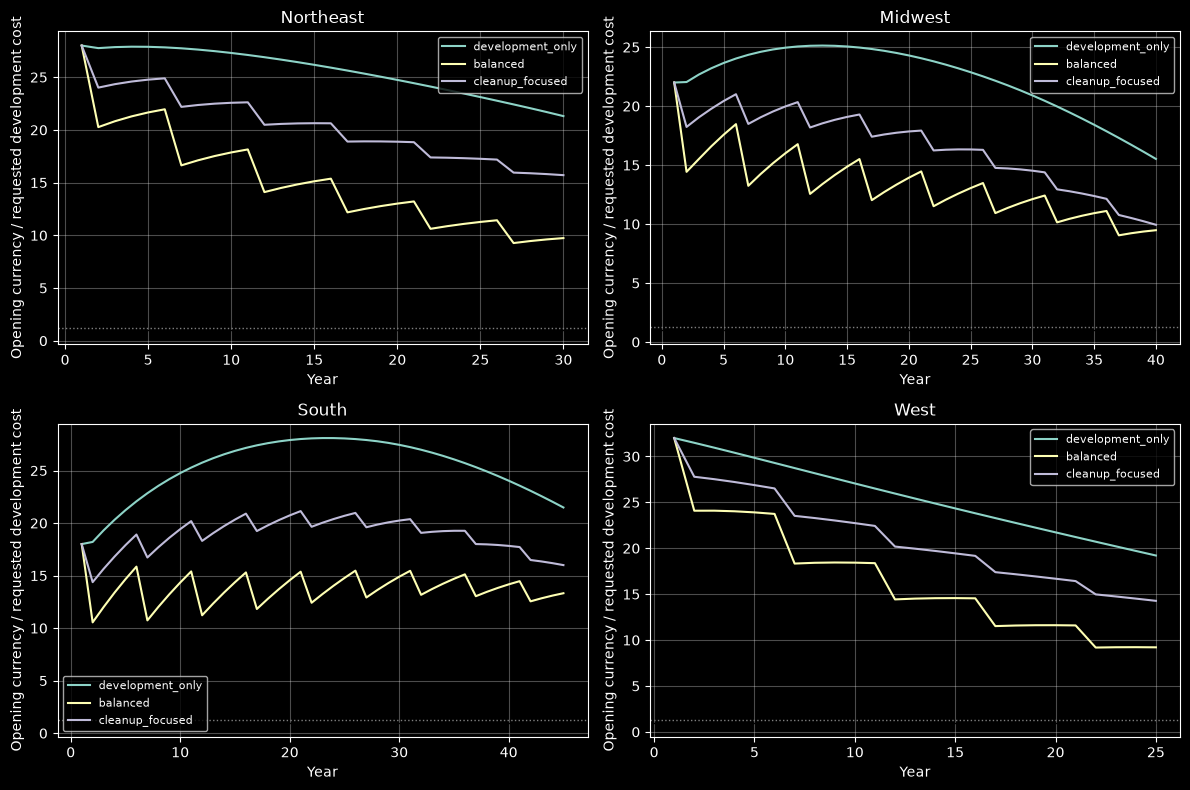

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for region_index, region in enumerate(REGIONAL_ECONOMIC_PARAMETERS):
    axis = axes.flat[region_index]
    region_rows = affordability_plot[affordability_plot["region"] == region["region"]]

    for policy_name in ("development_only", "balanced", "cleanup_focused"):
        policy_rows = region_rows[region_rows["policy"] == policy_name]
        axis.plot(policy_rows["year"], policy_rows["affordability_ratio"], label=policy_name)

    axis.axhline(1.0, color="black", linestyle="--", linewidth=1)
    axis.axhline(1.25, color="gray", linestyle=":", linewidth=1)
    axis.set_title(region["region"])
    axis.set_xlabel("Year")
    axis.set_ylabel("Opening currency / requested development cost")
    axis.grid(alpha=0.3)
    axis.legend(fontsize=8)

plt.tight_layout()
plt.show()

## What the affordability trace shows

Across all three cost shapes and policies, all 140 requested development points are purchased by year 60. There are no unaffordable development attempts and no requests with less than 25% headroom. Under the quadratic curve, the tightest cash-to-cost ratio is still 9.05: balanced Midwest has 816 currency units available at the start of year 37 for a 90.25-unit development cost. The ratio is even larger for every other region-policy combination.

The quadratic curve raises total development spending to 8,017 units, but 60-year cumulative net income ranges from 24,166 under development-only to 30,768 under balanced, before adding the 2,500 units of starting currency. In each region, cumulative net income is at least about twice its development spending. The one-point cost rises from 25 units at starting EDI to roughly 90-98 near EDI 100, while income and unspent currency accumulate over the long horizon.

The environment checks affordability before adding that year's income, so current-year income cannot fund the current action. Past income remains in currency and funds later development. Under these settings the cost curves reduce remaining currency but never become binding. The 20-, 40-, and 60-year results also show that reaching EDI 100 is a horizon effect: at 20 and 40 years, mean EDI remains below 100 for every cost curve.

## Does mitigation affect income and development?

The earlier saved result showed a small EDI advantage for balanced, but that result did not reproduce when all cells were rerun with the current code. In the refreshed 60-year quadratic run, both balanced and development-only reach EDI 100 in every region. This section compares their income and damage paths to check whether mitigation still supports income, even when it does not change final EDI.

The damage-off run is an ablation: it keeps pollution, development costs, investment costs, and policy choices, but removes pollution damage from income. The damage coefficients remain synthetic assumptions.

In [17]:
def collect_damage_diagnostics(trajectory, damage_multiplier, policy_name):
    annual_rows = []
    regional_rows = []

    cumulative_gross_income = 0.0
    cumulative_net_income = 0.0
    cumulative_income_damage = 0.0

    for info in trajectory:
        year = info["regional_economy"][0]["year"]

        year_gross_income = 0.0
        year_net_income = 0.0
        year_income_damage = 0.0
        year_development_spending = 0.0
        year_mitigation_spending = 0.0
        year_purchases = 0

        for region_result in info["regional_economy"]:
            gross_income = region_result["gross_income"]
            net_income = region_result["net_income"]
            income_damage = gross_income - net_income
            development_spending = region_result["development_cost"]
            mitigation_spending = region_result["investment_cost"]
            purchased = region_result["package_purchased"]

            cumulative_gross_income += gross_income
            cumulative_net_income += net_income
            cumulative_income_damage += income_damage

            year_gross_income += gross_income
            year_net_income += net_income
            year_income_damage += income_damage
            year_development_spending += development_spending
            year_mitigation_spending += mitigation_spending

            if purchased:
                year_purchases += 1

            row = {
                "income_damage_multiplier": damage_multiplier,
                "policy": policy_name,
                "year": year,
                "region": region_result["region"],
                "EDI": region_result["EDI"],
                "currency": region_result["currency"],
                "gross_income": gross_income,
                "net_income": net_income,
                "income_damage": income_damage,
                "damage_fraction": region_result["damage_fraction"],
                "PM2.5_damage_fraction": region_result["damage_by_pollutant"]["PM2.5"],
                "CO2_damage_fraction": region_result["damage_by_pollutant"]["CO2"],
                "Nitrate_damage_fraction": region_result["damage_by_pollutant"]["Nitrate-N"],
                "Lead_damage_fraction": region_result["damage_by_pollutant"]["Lead"],
                "development_spending": development_spending,
                "mitigation_spending": mitigation_spending,
                "package_purchased": purchased,
            }

            annual_rows.append(row)

        year_row = {
            "income_damage_multiplier": damage_multiplier,
            "policy": policy_name,
            "year": year,
            "total_gross_income": year_gross_income,
            "total_net_income": year_net_income,
            "total_income_damage": year_income_damage,
            "development_spending": year_development_spending,
            "mitigation_spending": year_mitigation_spending,
            "packages_purchased": year_purchases,
        }

        regional_rows.append(year_row)

    cumulative_results = {
        "cumulative_gross_income": cumulative_gross_income,
        "cumulative_net_income": cumulative_net_income,
        "cumulative_income_damage": cumulative_income_damage,
    }

    return annual_rows, regional_rows, cumulative_results

In [18]:
DIAGNOSTIC_POLICIES = ["development_only", "balanced"]
DAMAGE_MULTIPLIERS = [1.0, 0.0]
DIAGNOSTIC_HORIZON = 60

diagnostic_rows = []
annual_rows = []
regional_rows = []

for damage_multiplier in DAMAGE_MULTIPLIERS:
    for policy_name in DIAGNOSTIC_POLICIES:
        parameters = get_parameters(episode_steps=DIAGNOSTIC_HORIZON)
        config = EnvironmentConfig(parameters)

        environment = Study3IntegratedEnvironment(config, starting_currency_multiplier=STARTING_CURRENCY_MULTIPLIER, development_cost_shape="quadratic", income_damage_multiplier=damage_multiplier)

        trajectory, terminated, truncated = run_fixed_policy_episode(policy_name, environment, seed=0)

        summary = summarize_integrated_episode(policy_name, trajectory, environment)

        policy_annual_rows, policy_regional_rows, cumulative_results = collect_damage_diagnostics(trajectory, damage_multiplier, policy_name)

        annual_rows.extend(policy_annual_rows)
        regional_rows.extend(policy_regional_rows)

        summary["income_damage_multiplier"] = damage_multiplier
        summary["cumulative_gross_income"] = cumulative_results["cumulative_gross_income"]
        summary["cumulative_net_income"] = cumulative_results["cumulative_net_income"]
        summary["cumulative_income_damage"] = cumulative_results["cumulative_income_damage"]
        summary["terminated"] = terminated
        summary["completed_horizon"] = truncated

        diagnostic_rows.append(summary)

In [19]:
damage_diagnostic = pd.DataFrame(diagnostic_rows)
annual_diagnostic = pd.DataFrame(annual_rows)
regional_annual_diagnostic = pd.DataFrame(regional_rows)

diagnostic_columns = [
    "income_damage_multiplier", "policy", "final_mean_EDI", "final_min_EDI",
    "cumulative_gross_income", "cumulative_net_income", "cumulative_income_damage",
    "development_spending", "mitigation_spending", "investment_package_purchases",
    "final_mean_currency", "final_CO2_ppm", "final_mean_PM2.5_ug_m3",
    "final_mean_nitrate_mg_N_L", "final_mean_lead_total_kg",
]

display(damage_diagnostic[diagnostic_columns].round(3))

,income_damage_multiplier,policy,final_mean_EDI,final_min_EDI,cumulative_gross_income,cumulative_net_income,cumulative_income_damage,development_spending,mitigation_spending,investment_package_purchases,final_mean_currency,final_CO2_ppm,final_mean_PM2.5_ug_m3,final_mean_nitrate_mg_N_L,final_mean_lead_total_kg
0,1.0,development_only,100.0,100.0,26278.961,24165.780,2113.181,8017.169,0.0,0,4662.153,582.977,8.616,3.270,19.990
1,1.0,balanced,100.0,100.0,31668.517,30768.476,900.041,8017.169,9600.0,48,3912.827,578.460,8.572,2.494,11.415
2,0.0,development_only,100.0,100.0,36723.030,36723.030,0.000,8017.169,0.0,0,7801.465,582.977,8.616,3.270,19.990
3,0.0,balanced,100.0,100.0,36723.030,36723.030,0.000,8017.169,9600.0,48,5401.465,578.460,8.572,2.494,11.415


## Annual income and spending paths

The first table focuses on the South and reports annual income, modeled income loss from pollution, development spending, and mitigation spending. The second table summarizes all four regions by year. The plots make it easier to see whether mitigation spending is followed by lower damage and higher net income.

In [20]:
south_annual = annual_diagnostic[annual_diagnostic["region"] == "South"]
south_columns = ["income_damage_multiplier", "policy", "year", "EDI", "gross_income",
                 "net_income", "income_damage", "damage_fraction",
                 "development_spending", "mitigation_spending", "package_purchased", "currency"]
display(south_annual[south_columns].round(3))

,income_damage_multiplier,policy,year,EDI,gross_income,net_income,income_damage,damage_fraction,development_spending,mitigation_spending,package_purchased,currency
2,1.0,development_only,1,56.0,51.000,50.605,0.395,0.008,25.000,0.0,False,475.605
6,1.0,development_only,2,57.0,77.961,77.075,0.887,0.011,26.123,0.0,False,526.557
10,1.0,development_only,3,58.0,79.576,78.487,1.088,0.014,27.272,0.0,False,577.772
14,1.0,development_only,4,59.0,81.316,80.019,1.297,0.016,28.444,0.0,False,629.347
18,1.0,development_only,5,60.0,83.078,81.553,1.524,0.018,29.642,0.0,False,681.258
...,...,...,...,...,...,...,...,...,...,...,...,...
942,0.0,balanced,56,100.0,235.257,235.257,0.000,0.000,0.000,200.0,True,3693.339
946,0.0,balanced,57,100.0,239.492,239.492,0.000,0.000,0.000,0.0,False,3932.831
950,0.0,balanced,58,100.0,243.803,243.803,0.000,0.000,0.000,0.0,False,4176.634
954,0.0,balanced,59,100.0,248.191,248.191,0.000,0.000,0.000,0.0,False,4424.825


In [21]:
display(regional_annual_diagnostic.groupby(["income_damage_multiplier", "policy"]).agg(
    total_gross_income=("total_gross_income", "sum"),
    total_net_income=("total_net_income", "sum"),
    total_income_damage=("total_income_damage", "sum"),
    total_development_spending=("development_spending", "sum"),
    total_mitigation_spending=("mitigation_spending", "sum"),
    total_packages=("packages_purchased", "sum")).round(3))

total_gross_income  \
income_damage_multiplier policy                                 
0.0                      balanced                   36723.030   
                         development_only           36723.030   
1.0                      balanced                   31668.517   
                         development_only           26278.961   

                                           total_net_income  \
income_damage_multiplier policy                               
0.0                      balanced                 36723.030   
                         development_only         36723.030   
1.0                      balanced                 30768.476   
                         development_only         24165.780   

                                           total_income_damage  \
income_damage_multiplier policy                                  
0.0                      balanced                        0.000   
                         development_only                0.000   
1.0                      balanced                      900.041   
                         development_only             2113.181   

                                           total_development_spending  \
income_damage_multiplier policy                                         
0.0                      balanced                            8017.169   
                         development_only                    8017.169   
1.0                      balanced                            8017.169   
                         development_only                    8017.169   

                                           total_mitigation_spending  \
income_damage_multiplier policy                                        
0.0                      balanced                             9600.0   
                         development_only                        0.0   
1.0                      balanced                             9600.0   
                         development_only                        0.0   

                                           total_packages  
income_damage_multiplier policy                            
0.0                      balanced                      48  
                         development_only               0  
1.0                      balanced                      48  
                         development_only               0

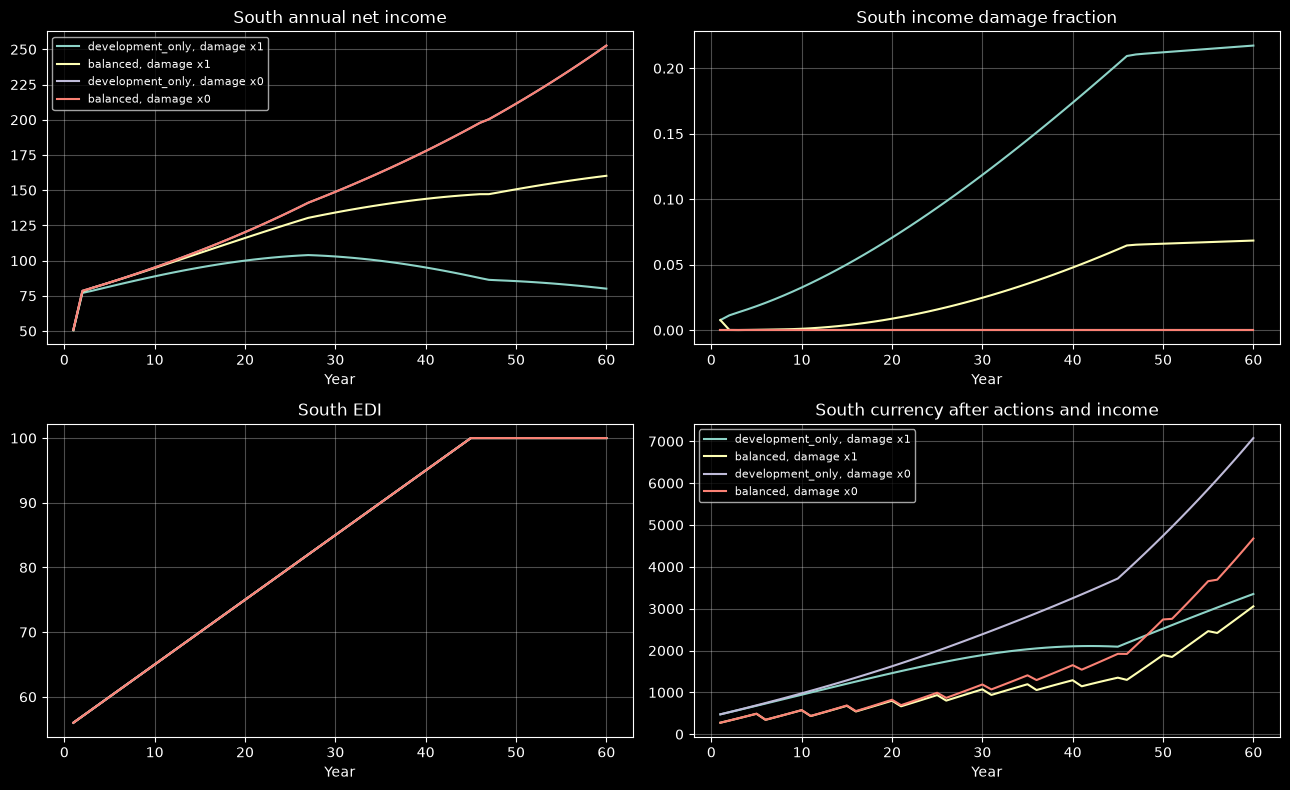

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for (damage_multiplier, policy_name), policy_rows in south_annual.groupby(["income_damage_multiplier", "policy"], sort=False):
    label = f"{policy_name}, damage x{damage_multiplier:g}"
    axes[0, 0].plot(policy_rows["year"], policy_rows["net_income"], label=label)
    axes[0, 1].plot(policy_rows["year"], policy_rows["damage_fraction"], label=label)
    axes[1, 0].plot(policy_rows["year"], policy_rows["EDI"], label=label)
    axes[1, 1].plot(policy_rows["year"], policy_rows["currency"], label=label)

axes[0, 0].set_title("South annual net income")
axes[0, 1].set_title("South income damage fraction")
axes[1, 0].set_title("South EDI")
axes[1, 1].set_title("South currency after actions and income")

for axis in axes.flat:
    axis.set_xlabel("Year")
    axis.grid(alpha=0.3)

axes[0, 0].legend(fontsize=8)
axes[1, 1].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [23]:
south_period_rows = []

periods = [("1-20", 1, 20), ("21-40", 21, 40), ("41-60", 41, 60)]

for damage_multiplier in DAMAGE_MULTIPLIERS:
    for policy_name in DIAGNOSTIC_POLICIES:
        damage_filter = annual_diagnostic["income_damage_multiplier"] == damage_multiplier
        policy_filter = annual_diagnostic["policy"] == policy_name
        region_filter = annual_diagnostic["region"] == "South"

        policy_south = annual_diagnostic[damage_filter & policy_filter & region_filter]

        for period_name, first_year, last_year in periods:
            period_filter = (policy_south["year"] >= first_year) & (policy_south["year"] <= last_year)
            period_rows = policy_south[period_filter]

            period_final = period_rows.iloc[-1]

            row = {
                "income_damage_multiplier": damage_multiplier,
                "policy": policy_name,
                "period": period_name,
                "gross_income": period_rows["gross_income"].sum(),
                "net_income": period_rows["net_income"].sum(),
                "income_damage": period_rows["income_damage"].sum(),
                "mean_damage_fraction": period_rows["damage_fraction"].mean(),
                "development_spending": period_rows["development_spending"].sum(),
                "mitigation_spending": period_rows["mitigation_spending"].sum(),
                "packages_purchased": period_rows["package_purchased"].sum(),
                "final_EDI": period_final["EDI"],
                "final_currency": period_final["currency"],
            }

            south_period_rows.append(row)

south_period_summary = pd.DataFrame(south_period_rows)
display(south_period_summary.round(3))

,income_damage_multiplier,policy,period,gross_income,net_income,income_damage,mean_damage_fraction,development_spending,mitigation_spending,packages_purchased,final_EDI,final_currency
0,1.0,development_only,1-20,1822.607,1752.082,70.524,0.036,741.605,0.0,0,75.0,1460.477
1,1.0,development_only,21-40,2302.632,2019.914,282.718,0.122,1378.642,0.0,0,95.0,2101.749
2,1.0,development_only,41-60,2168.130,1717.585,450.544,0.208,467.346,0.0,0,100.0,3351.989
3,1.0,balanced,1-20,1899.275,1893.411,5.864,0.003,741.605,800.0,4,75.0,801.806
4,1.0,balanced,21-40,2743.658,2667.606,76.052,0.027,1378.642,800.0,4,95.0,1290.770
5,1.0,balanced,41-60,3241.238,3033.026,208.213,0.064,467.346,800.0,4,100.0,3056.450
6,0.0,development_only,1-20,1916.121,1916.121,0.000,0.000,741.605,0.0,0,75.0,1624.516
7,0.0,development_only,21-40,3005.167,3005.167,0.000,0.000,1378.642,0.0,0,95.0,3251.041
8,0.0,development_only,41-60,4293.788,4293.788,0.000,0.000,467.346,0.0,0,100.0,7077.484
9,0.0,balanced,1-20,1916.121,1916.121,0.000,0.000,741.605,800.0,4,75.0,824.516


In [24]:
south_damage_components = south_annual[south_annual["income_damage_multiplier"] == 1.0]
damage_component_columns = ["PM2.5_damage_fraction", "CO2_damage_fraction", "Nitrate_damage_fraction", "Lead_damage_fraction"]
mean_damage_components = south_damage_components.groupby("policy")[damage_component_columns].mean()
display(mean_damage_components.round(5))

,PM2.5_damage_fraction,CO2_damage_fraction,Nitrate_damage_fraction,Lead_damage_fraction
policy,,,,
balanced,0.00002,0.00563,0.02589,0.00000
development_only,0.00009,0.00580,0.11056,0.00803


In [25]:
damage_filter = annual_diagnostic["income_damage_multiplier"] == 1.0
year_filter = annual_diagnostic["year"] == DIAGNOSTIC_HORIZON
reference_final_edi = annual_diagnostic[damage_filter & year_filter]
final_columns = ["policy", "region", "EDI", "currency"]
display(reference_final_edi[final_columns].round(3))

,policy,region,EDI,currency
236,development_only,Northeast,100.0,5982.923
237,development_only,Midwest,100.0,2891.519
238,development_only,South,100.0,3351.989
239,development_only,West,100.0,6422.181
476,balanced,Northeast,100.0,4622.301
477,balanced,Midwest,100.0,2929.009
478,balanced,South,100.0,3056.450
479,balanced,West,100.0,5043.547


In [26]:
selected_south_years = [1, 5, 10, 15, 20, 21, 25, 30, 40, 41, 45, 50, 60]
selected_south = south_annual[south_annual["year"].isin(selected_south_years)].copy()

selected_south_columns = ["income_damage_multiplier", "policy", "year", "EDI", "gross_income",
                          "net_income", "damage_fraction", "development_spending",
                          "mitigation_spending", "currency"]
display(selected_south[selected_south_columns].round(3))

,income_damage_multiplier,policy,year,EDI,gross_income,net_income,damage_fraction,development_spending,mitigation_spending,currency
2,1.0,development_only,1,56.0,51.000,50.605,0.008,25.000,0.0,475.605
18,1.0,development_only,5,60.0,83.078,81.553,0.018,29.642,0.0,681.258
38,1.0,development_only,10,65.0,91.833,88.837,0.033,36.000,0.0,944.149
58,1.0,development_only,15,70.0,100.150,95.120,0.050,42.975,0.0,1206.990
78,1.0,development_only,20,75.0,107.613,100.009,0.071,50.568,0.0,1460.477
82,1.0,development_only,21,76.0,108.969,100.791,0.075,52.160,0.0,1509.108
98,1.0,development_only,25,80.0,113.846,103.196,0.094,58.778,0.0,1693.591
118,1.0,development_only,30,85.0,116.803,102.953,0.119,67.605,0.0,1891.016
158,1.0,development_only,40,95.0,115.155,95.148,0.174,87.111,0.0,2101.749
162,1.0,development_only,41,96.0,114.605,94.026,0.180,89.198,0.0,2106.578


## What this comparison shows

With reference damage and quadratic development costs, both policies reach mean EDI 100 at year 60. Balanced spends 9,600 on mitigation and completes 48 of 48 scheduled packages. Balanced ends with lower pollution and higher cumulative net income (30,768 versus 24,166 currency units), while cumulative modeled income damage is lower (900 versus 2,113 units). The difference is not an EDI gain in this rerun because both policies reach the ceiling.

When income damage is removed, both policies have identical EDI and cumulative gross income. This is consistent with mitigation increasing modeled income by reducing environmental damage. The result depends on synthetic damage equations and does not establish a real-world economic effect.